In [1]:
print("Final analysis notebook working")

Final analysis notebook working


In [2]:

# ASSIGNMENT 02 — VERIFY ALL TRAINING HISTORIES
# Read-only; no training or inference.

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/kaggle/input/datasets/nayebul0/"
    "assignment02-training-history-recovery"
)

FOLDERS = [
    "EfficientNet-B3_D1",
    "EfficientNet-B3_D2",
    "EfficientNetB0_D1",
    "EfficientNetB0_D2",
    "MobileNetV2_D1",
    "MobileNetV2_D2",
    "MobileNetV3_D1",
    "MobileNetV3_D2"
]

STAGES = [
    "stage_a_history.csv",
    "stage_b_history.csv"
]

print("=" * 65)
print("ASSIGNMENT 02 — TRAINING HISTORY VERIFICATION")
print("=" * 65)

verified = 0

for folder in FOLDERS:
    for stage in STAGES:

        matches = list(
            ROOT.rglob(f"{folder}/{stage}")
        )

        if len(matches) != 1:
            print(
                f"MISSING OR DUPLICATE: {folder}/{stage}"
            )
            continue

        path = matches[0]
        df = pd.read_csv(path)

        if df.empty:
            print(f"EMPTY: {folder}/{stage}")
            continue

        verified += 1

        print(
            f"{folder} | {stage} | "
            f"epochs={len(df)} | "
            f"columns={df.columns.tolist()}"
        )

print("\n" + "=" * 65)
print(f"Readable nonempty histories: {verified}/16")

if verified == 16:
    print("ALL 16 TRAINING HISTORIES VERIFIED")
else:
    print("HISTORY VERIFICATION INCOMPLETE")

print("NO TRAINING OR INFERENCE PERFORMED")


ASSIGNMENT 02 — TRAINING HISTORY VERIFICATION
EfficientNet-B3_D1 | stage_a_history.csv | epochs=5 | columns=['epoch', 'train_loss', 'train_acc', 'train_precision_macro', 'train_recall_macro', 'train_f1_macro', 'val_loss', 'val_acc', 'val_precision_macro', 'val_recall_macro', 'val_f1_macro', 'epoch_time_sec']
EfficientNet-B3_D1 | stage_b_history.csv | epochs=3 | columns=['epoch', 'train_loss', 'train_acc', 'train_precision_macro', 'train_recall_macro', 'train_f1_macro', 'val_loss', 'val_acc', 'val_precision_macro', 'val_recall_macro', 'val_f1_macro', 'epoch_time_sec']
EfficientNet-B3_D2 | stage_a_history.csv | epochs=5 | columns=['epoch', 'train_loss', 'train_acc', 'train_precision_macro', 'train_recall_macro', 'train_f1_macro', 'val_loss', 'val_acc', 'val_precision_macro', 'val_recall_macro', 'val_f1_macro', 'epoch_time_sec']
EfficientNet-B3_D2 | stage_b_history.csv | epochs=3 | columns=['epoch', 'train_loss', 'train_acc', 'train_precision_macro', 'train_recall_macro', 'train_f1_macro'

ASSIGNMENT 02 — GENERATING GENUINE LEARNING CURVES


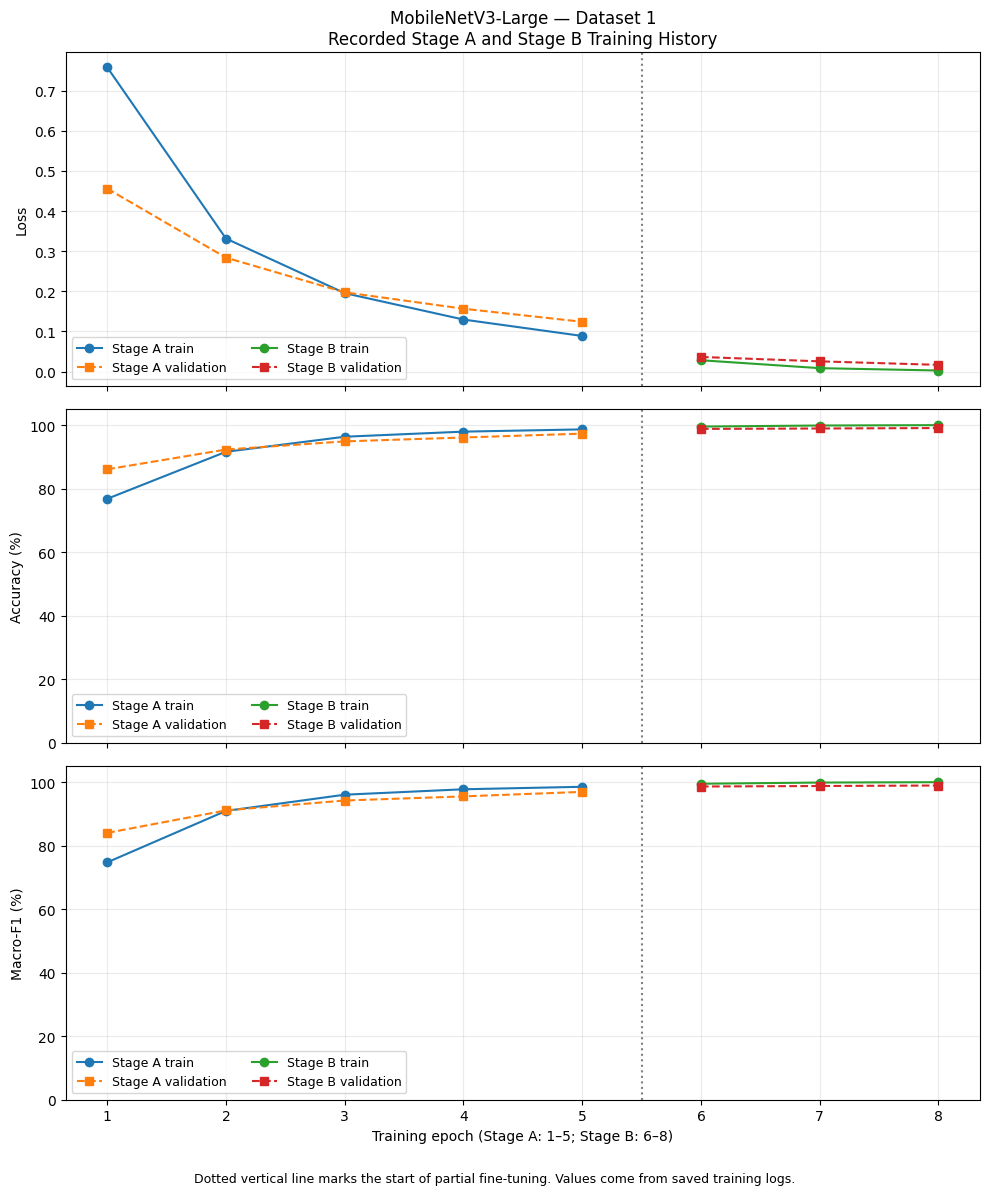

VERIFIED D1_MobileNetV3: 5 Stage A epochs + 3 Stage B epochs | figure saved


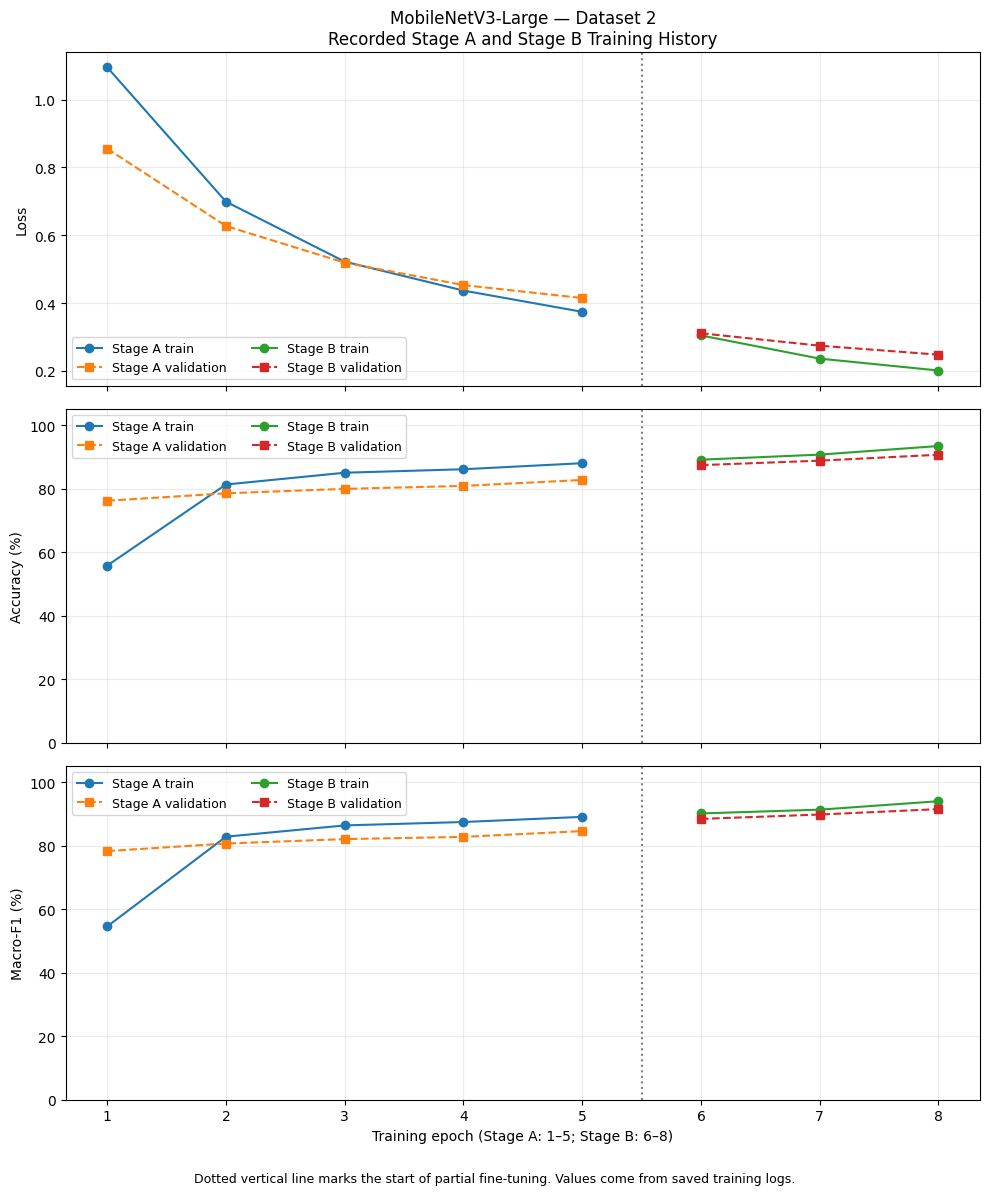

VERIFIED D2_MobileNetV3: 5 Stage A epochs + 3 Stage B epochs | figure saved


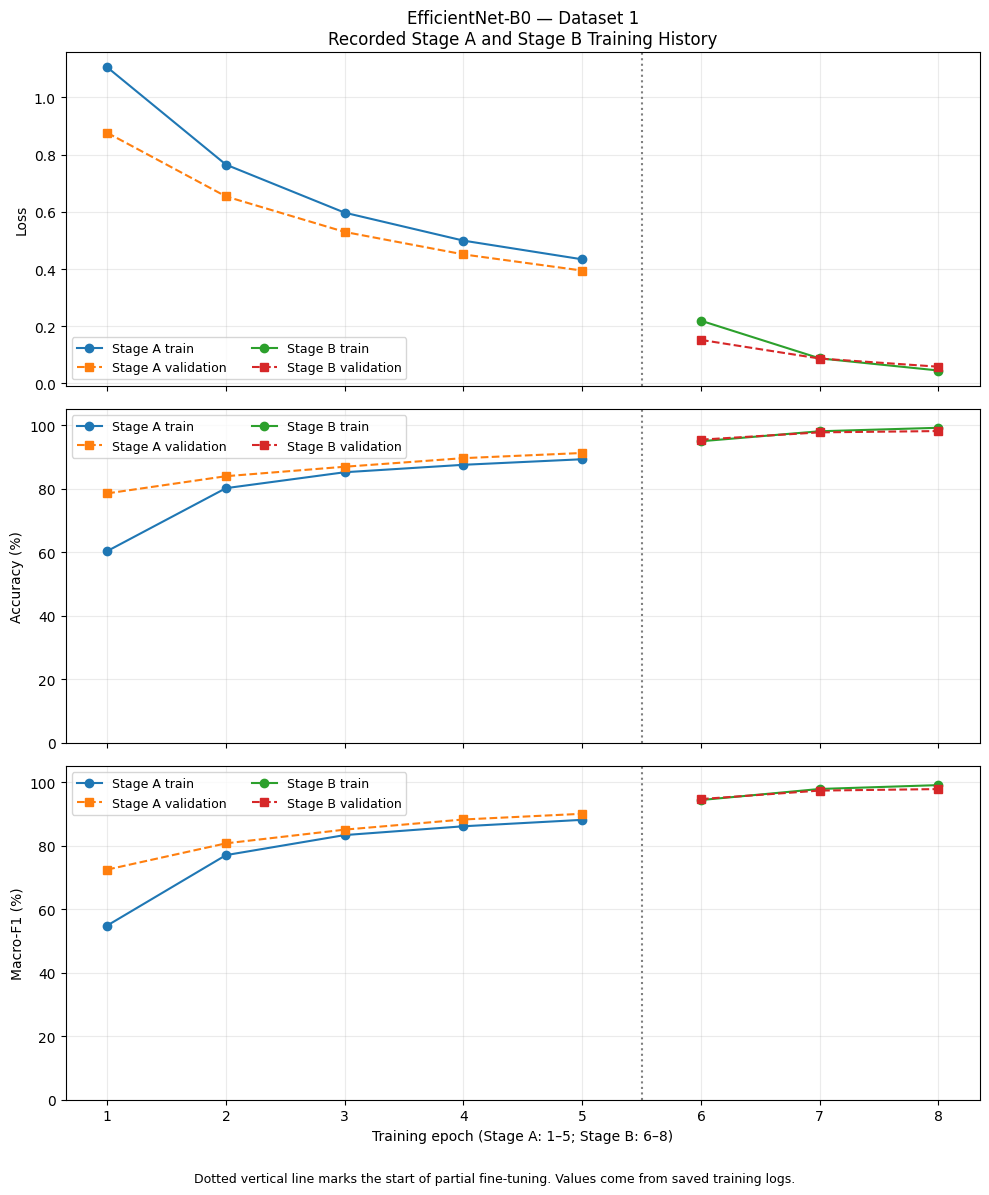

VERIFIED D1_EfficientNetB0: 5 Stage A epochs + 3 Stage B epochs | figure saved


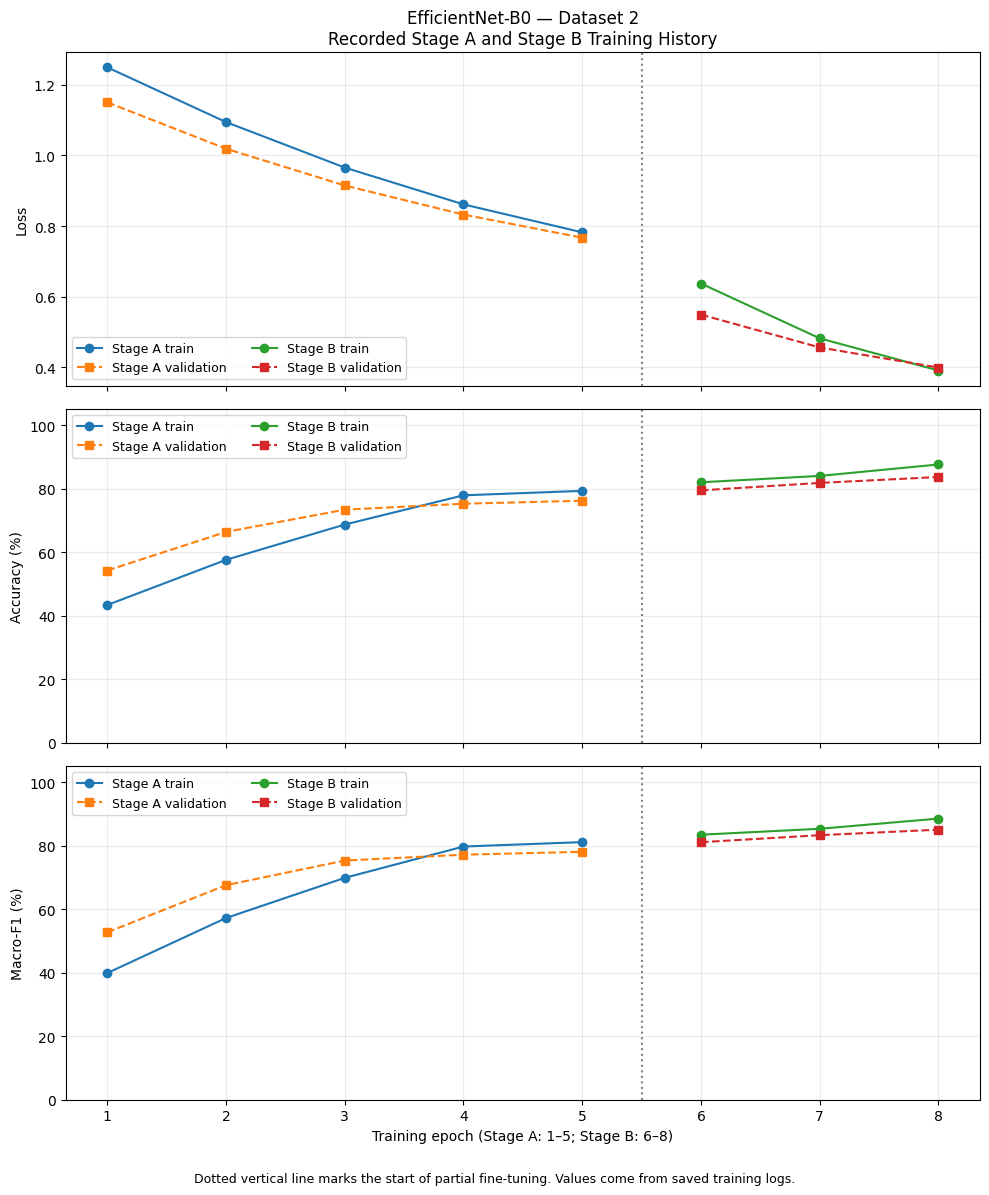

VERIFIED D2_EfficientNetB0: 5 Stage A epochs + 3 Stage B epochs | figure saved


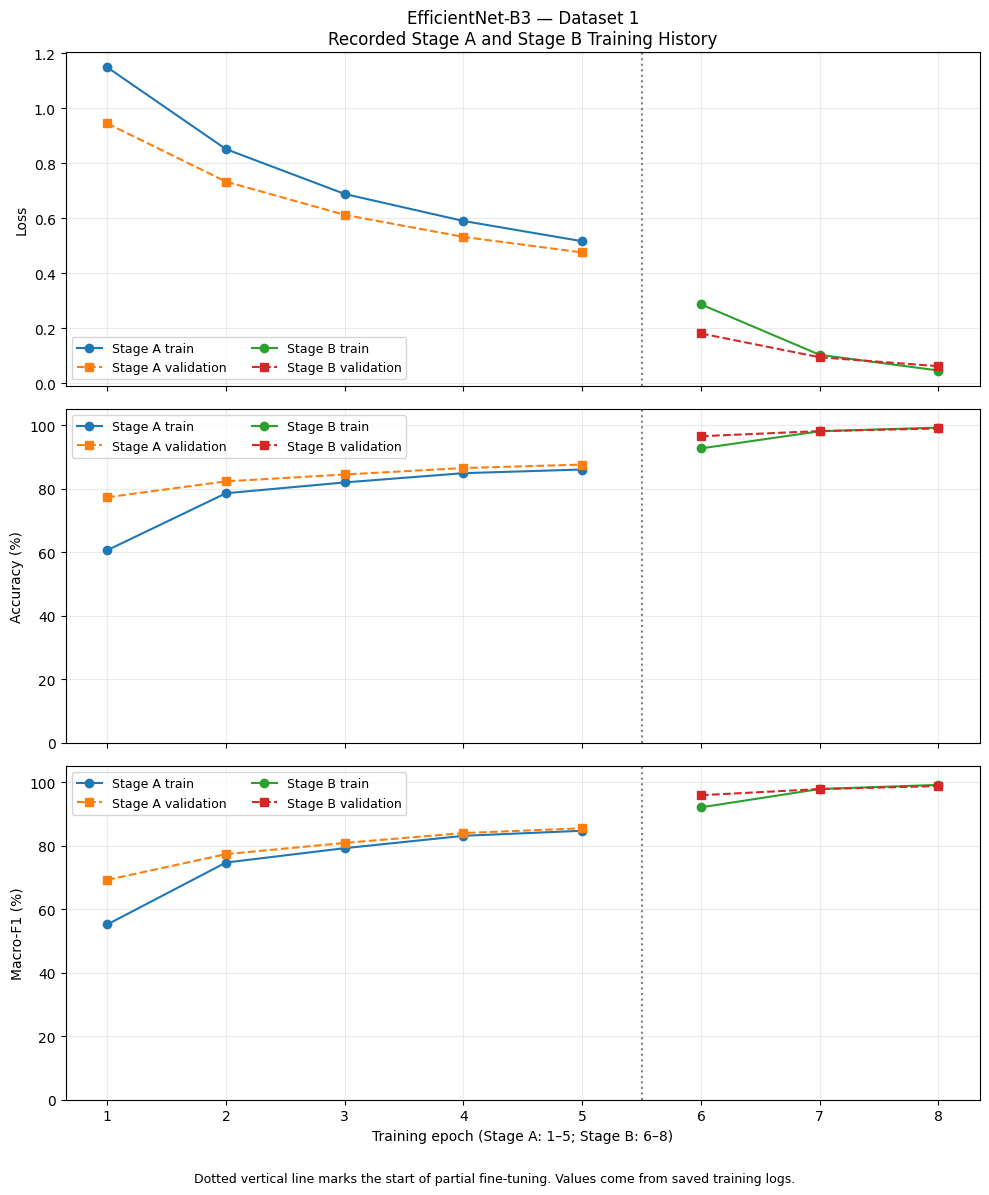

VERIFIED D1_EfficientNetB3: 5 Stage A epochs + 3 Stage B epochs | figure saved


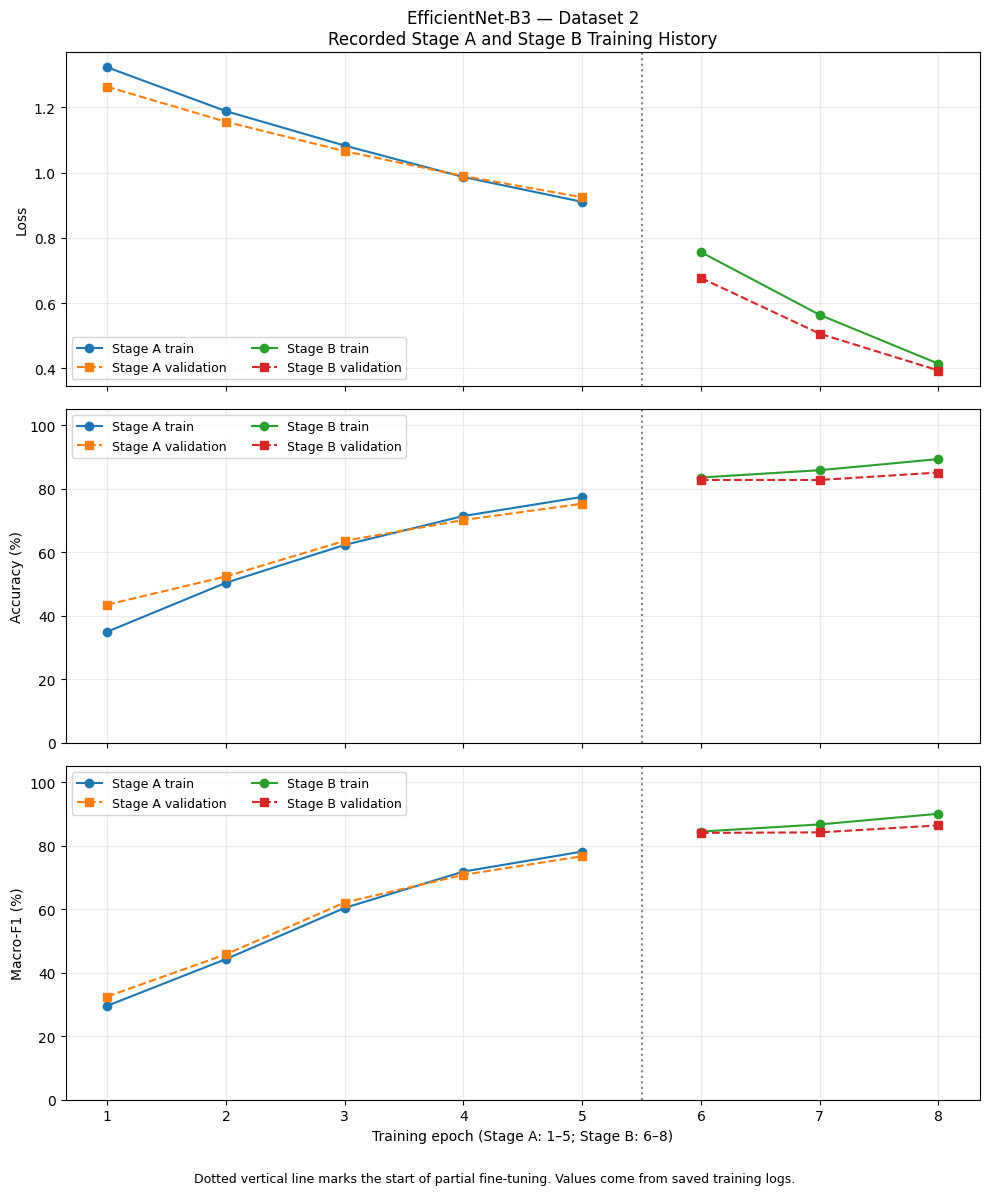

VERIFIED D2_EfficientNetB3: 5 Stage A epochs + 3 Stage B epochs | figure saved


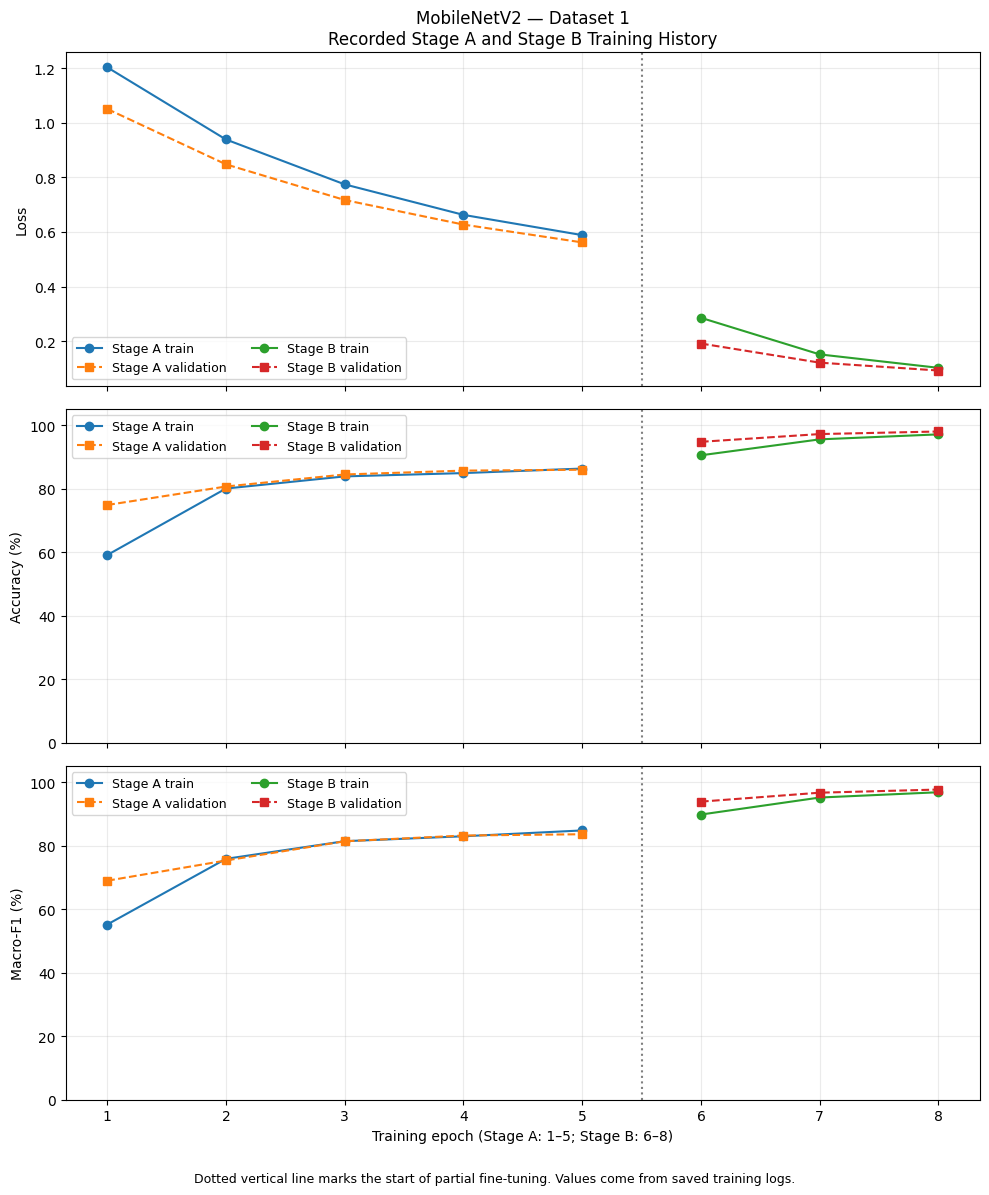

VERIFIED D1_MobileNetV2: 5 Stage A epochs + 3 Stage B epochs | figure saved


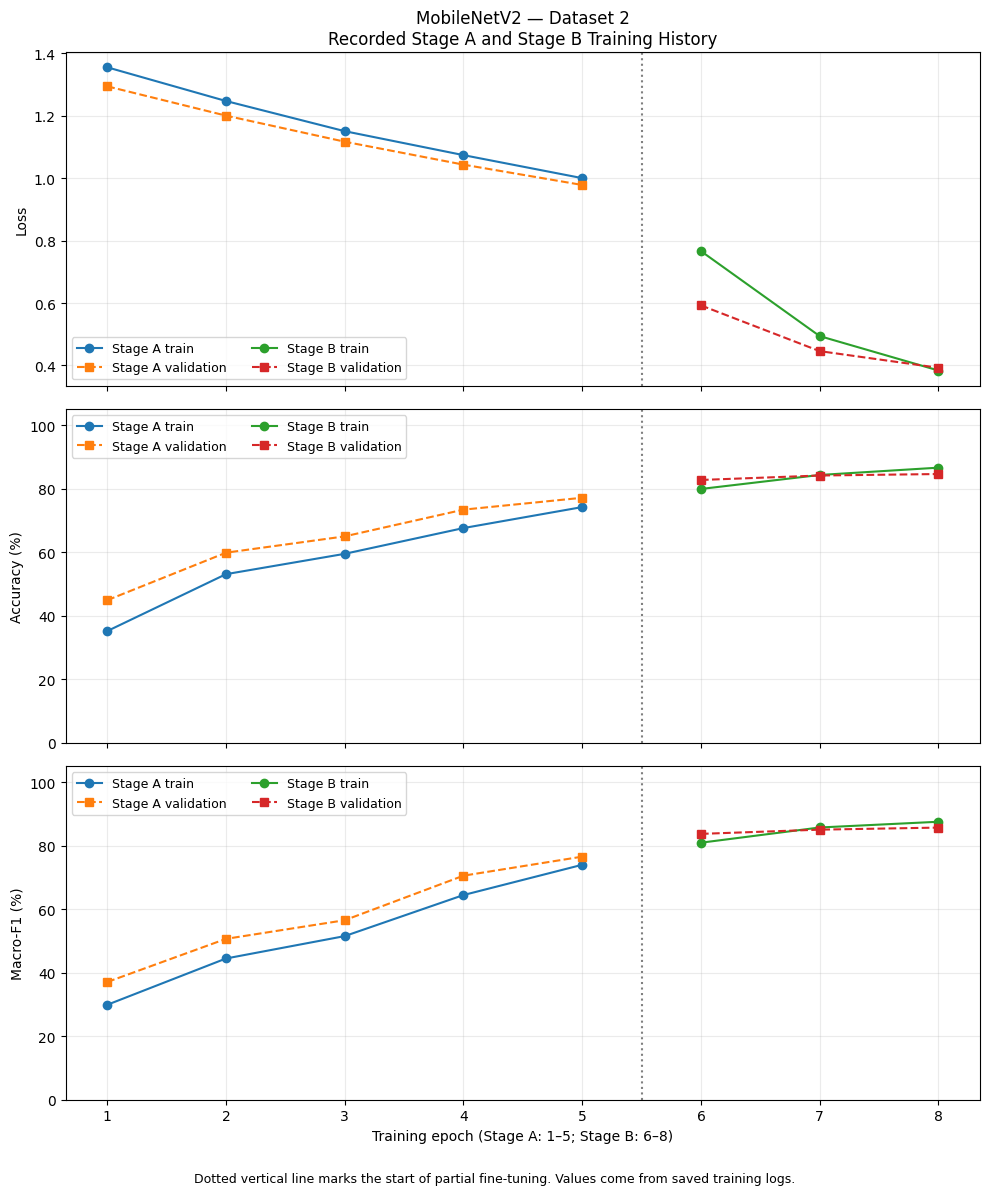

VERIFIED D2_MobileNetV2: 5 Stage A epochs + 3 Stage B epochs | figure saved

RECORDED STAGE B FINAL-EPOCH VALIDATION MACRO-F1
       experiment  final_val_accuracy  final_val_macro_f1
   D1_MobileNetV3              0.9905              0.9892
   D2_MobileNetV3              0.9065              0.9149
D1_EfficientNetB0              0.9811              0.9779
D2_EfficientNetB0              0.8364              0.8502
D1_EfficientNetB3              0.9892              0.9875
D2_EfficientNetB3              0.8505              0.8636
   D1_MobileNetV2              0.9797              0.9765
   D2_MobileNetV2              0.8458              0.8567

Note: Final-epoch validation metrics are not necessarily best-checkpoint metrics.

TRAINING CURVES COMPLETED
Experiments verified: 8
History CSV sources verified: 16
Epoch records consolidated: 64
Learning-curve figures created: 8
Total files packaged: 20

Backup ZIP: /kaggle/working/Assignment02_Training_Curves.zip

NO TRAINING OR INFERENCE REPEATE

In [3]:

# ============================================================
# ADVANCED MACHINE LEARNING — ASSIGNMENT 02
# FINAL TRAINING AND VALIDATION LEARNING CURVES
#
# 4 selected models × 2 datasets = 8 experiments
# Stage A: 5 recorded epochs
# Stage B: 3 recorded epochs
#
# Source: Original saved training-history CSV files
# NO TRAINING, INFERENCE, OR MODIFICATION OF SOURCE FILES
# ============================================================

from pathlib import Path
import hashlib
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Input and output paths
# ------------------------------------------------------------
INPUT_ROOT = Path(
    "/kaggle/input/datasets/nayebul0/"
    "assignment02-training-history-recovery"
)

OUTPUT_DIR = Path(
    "/kaggle/working/"
    "assignment02_training_curves"
)

ZIP_PATH = Path(
    "/kaggle/working/"
    "Assignment02_Training_Curves.zip"
)

assert INPUT_ROOT.is_dir(), (
    "Training-history dataset is not attached."
)

assert not OUTPUT_DIR.exists(), (
    "Output folder already exists. "
    "Inspect previous results instead of overwriting."
)

assert not ZIP_PATH.exists(), (
    "Training-curves ZIP already exists."
)

# ------------------------------------------------------------
# 2. Experiment mapping: EXACT uploaded folder names
# ------------------------------------------------------------
EXPERIMENTS = [
    ("MobileNetV3_D1", "D1_MobileNetV3", "MobileNetV3-Large", "Dataset 1"),
    ("MobileNetV3_D2", "D2_MobileNetV3", "MobileNetV3-Large", "Dataset 2"),

    ("EfficientNetB0_D1", "D1_EfficientNetB0", "EfficientNet-B0", "Dataset 1"),
    ("EfficientNetB0_D2", "D2_EfficientNetB0", "EfficientNet-B0", "Dataset 2"),

    ("EfficientNet-B3_D1", "D1_EfficientNetB3", "EfficientNet-B3", "Dataset 1"),
    ("EfficientNet-B3_D2", "D2_EfficientNetB3", "EfficientNet-B3", "Dataset 2"),

    ("MobileNetV2_D1", "D1_MobileNetV2", "MobileNetV2", "Dataset 1"),
    ("MobileNetV2_D2", "D2_MobileNetV2", "MobileNetV2", "Dataset 2")
]

STAGES = [
    ("A", "stage_a_history.csv", 5),
    ("B", "stage_b_history.csv", 3)
]

# ------------------------------------------------------------
# 3. CSV column-name normalization
# ------------------------------------------------------------
COLUMN_ALIASES = {
    "train_acc": "train_accuracy",
    "val_acc": "val_accuracy",

    "train_f1_macro": "train_macro_f1",
    "val_f1_macro": "val_macro_f1",

    "epoch_time_sec": "epoch_time_seconds",
    "elapsed_seconds": "epoch_time_seconds"
}

REQUIRED = [
    "epoch",
    "train_loss",
    "val_loss",
    "train_accuracy",
    "val_accuracy",
    "train_macro_f1",
    "val_macro_f1"
]

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

def load_history(folder_name, filename, expected_epochs):
    matches = list(
        INPUT_ROOT.rglob(
            f"{folder_name}/{filename}"
        )
    )

    assert len(matches) == 1, (
        f"Expected exactly one CSV for "
        f"{folder_name}/{filename}; found {len(matches)}."
    )

    path = matches[0]
    original = pd.read_csv(path)

    assert len(original) == expected_epochs, (
        f"{folder_name}/{filename}: "
        f"expected {expected_epochs} epochs; "
        f"found {len(original)}."
    )

    normalized = original.rename(
        columns=COLUMN_ALIASES
    ).copy()

    assert len(normalized.columns) == len(
        set(normalized.columns)
    ), (
        f"Duplicate columns after normalization: {path}"
    )

    missing = set(REQUIRED) - set(
        normalized.columns
    )

    assert not missing, (
        f"Missing columns in {path}: {sorted(missing)}"
    )

    for column in REQUIRED:
        normalized[column] = pd.to_numeric(
            normalized[column],
            errors="raise"
        )

    assert np.isfinite(
        normalized[REQUIRED].to_numpy(dtype=float)
    ).all(), (
        f"Non-finite training values in {path}"
    )

    # Verify metrics are proportions, not percentages.
    metric_columns = [
        "train_accuracy",
        "val_accuracy",
        "train_macro_f1",
        "val_macro_f1"
    ]

    for column in metric_columns:
        assert normalized[column].between(
            0, 1
        ).all(), (
            f"Unexpected metric range: {path}, {column}"
        )

    assert (
        normalized["train_loss"] >= 0
    ).all()

    assert (
        normalized["val_loss"] >= 0
    ).all()

    # Require strictly increasing recorded epoch labels.
    epochs = normalized["epoch"].to_numpy()

    assert np.all(np.diff(epochs) > 0), (
        f"Epoch order is invalid: {path}"
    )

    # Preserve original epoch labels separately.
    normalized["recorded_epoch"] = normalized["epoch"]

    return normalized, path

# ------------------------------------------------------------
# 4. Load, verify, and combine the two stages
# ------------------------------------------------------------
all_histories = []
source_records = []
figure_paths = []

print("=" * 72)
print("ASSIGNMENT 02 — GENERATING GENUINE LEARNING CURVES")
print("=" * 72)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False
)

for folder, experiment, model, dataset in EXPERIMENTS:

    stage_tables = []

    for stage, filename, expected_epochs in STAGES:

        history, source_path = load_history(
            folder,
            filename,
            expected_epochs
        )

        history["stage"] = stage
        history["experiment"] = experiment
        history["model"] = model
        history["dataset"] = dataset

        stage_tables.append(history)

        source_records.append({
            "experiment": experiment,
            "stage": stage,
            "source_path": str(source_path),
            "sha256": sha256_file(source_path),
            "recorded_epochs": len(history),
            "original_columns": pd.read_csv(
                source_path,
                nrows=0
            ).columns.tolist()
        })

    stage_a, stage_b = stage_tables

    # Use sequential plotting positions, retaining
    # the real recorded epoch labels in the CSV.
    stage_a = stage_a.copy()
    stage_b = stage_b.copy()

    stage_a["training_epoch"] = np.arange(
        1, len(stage_a) + 1
    )

    stage_b["training_epoch"] = np.arange(
        len(stage_a) + 1,
        len(stage_a) + len(stage_b) + 1
    )

    combined = pd.concat(
        [stage_a, stage_b],
        ignore_index=True
    )

    assert len(combined) == 8

    all_histories.append(combined)

    combined.to_csv(
        OUTPUT_DIR / f"{experiment}_combined_history.csv",
        index=False
    )

    # --------------------------------------------------------
    # 5. Create one figure per experiment
    # --------------------------------------------------------
    metric_panels = [
        (
            "train_loss",
            "val_loss",
            "Loss",
            False
        ),
        (
            "train_accuracy",
            "val_accuracy",
            "Accuracy (%)",
            True
        ),
        (
            "train_macro_f1",
            "val_macro_f1",
            "Macro-F1 (%)",
            True
        )
    ]

    fig, axes = plt.subplots(
        3, 1,
        figsize=(10, 12),
        sharex=True
    )

    for ax, (
        train_column,
        val_column,
        ylabel,
        percentage
    ) in zip(axes, metric_panels):

        for stage_df, stage_label in [
            (stage_a, "Stage A"),
            (stage_b, "Stage B")
        ]:

            x = stage_df[
                "training_epoch"
            ].to_numpy()

            multiplier = (
                100 if percentage else 1
            )

            train_values = (
                stage_df[train_column].to_numpy()
                * multiplier
            )

            val_values = (
                stage_df[val_column].to_numpy()
                * multiplier
            )

            ax.plot(
                x,
                train_values,
                marker="o",
                linestyle="-",
                label=f"{stage_label} train"
            )

            ax.plot(
                x,
                val_values,
                marker="s",
                linestyle="--",
                label=f"{stage_label} validation"
            )

        # Boundary between epoch 5 and epoch 6.
        ax.axvline(
            x=5.5,
            color="gray",
            linestyle=":",
            linewidth=1.5
        )

        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)

        if percentage:
            ax.set_ylim(0, 105)

        ax.legend(
            loc="best",
            fontsize=9,
            ncol=2
        )

    axes[0].set_title(
        f"{model} — {dataset}\n"
        "Recorded Stage A and Stage B Training History"
    )

    axes[-1].set_xlabel(
        "Training epoch (Stage A: 1–5; Stage B: 6–8)"
    )

    axes[-1].set_xticks(
        np.arange(1, 9)
    )

    fig.text(
        0.5,
        0.01,
        "Dotted vertical line marks the start "
        "of partial fine-tuning. "
        "Values come from saved training logs.",
        ha="center",
        fontsize=9
    )

    fig.tight_layout(
        rect=[0, 0.03, 1, 1]
    )

    figure_path = (
        OUTPUT_DIR
        / f"{experiment}_learning_curves.png"
    )

    fig.savefig(
        figure_path,
        dpi=220,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    figure_paths.append(figure_path)

    print(
        f"VERIFIED {experiment}: "
        f"5 Stage A epochs + "
        f"3 Stage B epochs | "
        f"figure saved"
    )

# ------------------------------------------------------------
# 6. Consolidated training-history CSV
# ------------------------------------------------------------
full_history = pd.concat(
    all_histories,
    ignore_index=True
)

assert len(full_history) == 64

full_history.to_csv(
    OUTPUT_DIR / "all_experiments_training_history.csv",
    index=False
)

sources_df = pd.DataFrame(source_records)

assert len(sources_df) == 16

sources_df.to_csv(
    OUTPUT_DIR / "training_history_sources.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Summarize recorded final-epoch values
# ------------------------------------------------------------
final_epoch_rows = []

for (
    experiment,
    stage
), subset in full_history.groupby(
    ["experiment", "stage"],
    sort=False
):

    last = subset.sort_values(
        "training_epoch"
    ).iloc[-1]

    final_epoch_rows.append({
        "experiment": experiment,
        "dataset": str(last["dataset"]),
        "model": str(last["model"]),
        "stage": stage,
        "last_training_epoch": int(
            last["training_epoch"]
        ),
        "final_train_loss": float(
            last["train_loss"]
        ),
        "final_val_loss": float(
            last["val_loss"]
        ),
        "final_train_accuracy": float(
            last["train_accuracy"]
        ),
        "final_val_accuracy": float(
            last["val_accuracy"]
        ),
        "final_train_macro_f1": float(
            last["train_macro_f1"]
        ),
        "final_val_macro_f1": float(
            last["val_macro_f1"]
        )
    })

final_epochs_df = pd.DataFrame(
    final_epoch_rows
)

assert len(final_epochs_df) == 16

final_epochs_df.to_csv(
    OUTPUT_DIR / "stage_final_epoch_summary.csv",
    index=False
)

print("\n" + "=" * 72)
print("RECORDED STAGE B FINAL-EPOCH VALIDATION MACRO-F1")
print("=" * 72)

stage_b_final = final_epochs_df.loc[
    final_epochs_df["stage"] == "B",
    [
        "experiment",
        "final_val_accuracy",
        "final_val_macro_f1"
    ]
]

print(
    stage_b_final.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print(
    "\nNote: Final-epoch validation metrics are "
    "not necessarily best-checkpoint metrics."
)

# ------------------------------------------------------------
# 8. Save provenance and limitation notes
# ------------------------------------------------------------
verification = {
    "analysis": "Actual recorded learning curves",
    "selected_models": [
        "MobileNetV3-Large",
        "EfficientNet-B0",
        "EfficientNet-B3",
        "MobileNetV2"
    ],
    "dataset_count": 2,
    "experiment_count": 8,
    "history_csv_count": 16,
    "total_epoch_records": 64,
    "stage_a_epochs_per_experiment": 5,
    "stage_b_epochs_per_experiment": 3,
    "source_records": source_records,
    "training_repeated": False,
    "test_inference_repeated": False,
    "source_files_modified": False,
    "interpretation_notes": [
        "Training and validation values are taken from "
        "the original saved history CSV files.",
        "Stage A and Stage B represent different "
        "training configurations.",
        "Epochs are positioned sequentially for plots; "
        "original epoch labels remain in CSV outputs.",
        "Final logged epoch is not necessarily "
        "the selected best-validation checkpoint.",
        "These plots are descriptive and do not "
        "repair potential split contamination.",
        "Dataset 1 and Dataset 2 use different classes."
    ]
}

with open(
    OUTPUT_DIR / "training_curves_verification.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        verification,
        file,
        indent=2
    )

# ------------------------------------------------------------
# 9. Check outputs and create ZIP backup
# ------------------------------------------------------------
required_files = [
    "all_experiments_training_history.csv",
    "training_history_sources.csv",
    "stage_final_epoch_summary.csv",
    "training_curves_verification.json"
]

required_files += [
    f"{experiment}_combined_history.csv"
    for _, experiment, _, _ in EXPERIMENTS
]

required_files += [
    f"{experiment}_learning_curves.png"
    for _, experiment, _, _ in EXPERIMENTS
]

assert len(required_files) == 20

for name in required_files:
    path = OUTPUT_DIR / name
    assert path.is_file(), f"Missing output: {name}"
    assert path.stat().st_size > 0

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for name in required_files:
        archive.write(
            OUTPUT_DIR / name,
            arcname=name
        )

with zipfile.ZipFile(
    ZIP_PATH
) as archive:
    assert archive.testzip() is None
    assert set(archive.namelist()) == set(
        required_files
    )

print("\n" + "=" * 72)
print("TRAINING CURVES COMPLETED")
print("=" * 72)

print("Experiments verified: 8")
print("History CSV sources verified: 16")
print("Epoch records consolidated: 64")
print("Learning-curve figures created: 8")
print("Total files packaged:", len(required_files))

print("\nBackup ZIP:", ZIP_PATH)

print("\nNO TRAINING OR INFERENCE REPEATED")
